# Review 1 EDA ? ArunN2005

Issues **#63, #64, #66, #65** on `EDA_Arun`. The order runs input checks first and G9 last.
All calculations use the existing processed feature files; source data stays read only.

This notebook runs the analysis module, displays representative outputs, and validates
all exports. Read [`EDA_doc/EDA_findings.md`](../EDA_doc/EDA_findings.md) for the
complete findings and evidence, and [`EDA_doc/README.md`](../EDA_doc/README.md)
for definitions, control selection, and limitations. Install `requirements.txt` first.

## Setup and data scope

138 Manhattan/Queens zones, Sep 8 2025?Feb 28 2026: 576,288 zone-hours including zeros.
Yellow and green pickups are pooled. The first seven days were removed by the existing
processing pipeline. New York timestamps are naive; the repeated DST hour is combined.
The implementation is in [`eda_arun.py`](eda_arun.py), so CLI and notebook use the same calculations.

In [1]:
from pathlib import Path
import sys
from IPython.display import display, Image, Markdown
import pandas as pd

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'scripts/eda_arun.py').exists())
sys.path.insert(0, str(ROOT / 'scripts'))
import eda_arun as eda
from validate_eda_arun import validate

data, zones = eda.load_data()
print(f'{len(data):,} rows; {data.PULocationID.nunique()} zones')
print(f'{data.pickup_hour.min()} to {data.pickup_hour.max()}')
display(data.head(3))

576,288 rows; 138 zones
2025-09-08 00:00:00 to 2026-02-28 23:00:00


,PULocationID,pickup_hour,trip_count,apparent_temperature,rain,snowfall,precipitation_probability,hour,day_of_week,month,...,trip_count_roll_24h,LocationID,Borough,Zone,service_zone,latitude,longitude,date,year_month,week_start
0,2,2025-09-08 00:00:00,0,13.8,0.0,0.0,0,0,0,9,...,0.0,2,Queens,Jamaica Bay,Boro Zone,40.61675,-73.8313,2025-09-08,2025-09,2025-09-08
1,2,2025-09-08 01:00:00,0,13.5,0.0,0.0,0,1,0,9,...,0.0,2,Queens,Jamaica Bay,Boro Zone,40.61675,-73.8313,2025-09-08,2025-09,2025-09-08
2,2,2025-09-08 02:00:00,0,13.5,0.0,0.0,0,2,0,9,...,0.0,2,Queens,Jamaica Bay,Boro Zone,40.61675,-73.8313,2025-09-08,2025-09,2025-09-08


## #63 ? Data checks and target distribution

Validate schema, the complete grid, flags, borough splits, ranges and weather joins.
Recover the removed Sep 1?7 demand once using lag_168h in Sep 8?14, then reconcile
with the cleaning report. Keep zero rows; plot distributions, sparse areas and DST.
Weather-cell identity uses horizontal grid coordinates, not elevation.

#63: 15 checks passed; retained 21,728,117 + warm-up 851,676 = clean 22,579,793.


,check,passed,detail
0,A1 schema and nulls,True,17 expected columns; zero nulls
1,A2 unique zone-hours,True,"576,288 rows"
2,A2 complete rectangular grid,True,"138 zones x 4,176 local hour labels = 576,288"
3,A1 numeric and Boolean types,True,"integer counts/calendar, float weather/rolling..."
4,A3 finite values,True,all numeric fields finite
5,A3 count and weather ranges,True,nonnegative counts/rain/snow; probability 0--1...
6,A3 calendar derivation,True,matches pickup_hour
7,A5 weekend and holiday flags,True,"23,184 holiday rows; 7 dates; Labor Day is in ..."
8,A6 Manhattan exact split,True,"288,144 rows; all columns and values compared"
9,A6 Queens exact split,True,"288,144 rows; all columns and values compared"


,stage,trips
0,Raw,23318979
1,Removed in cleaning,739186
2,Clean,22579793
3,Warm-up (recovered from 168h lag),851676
4,Retained features,21728117


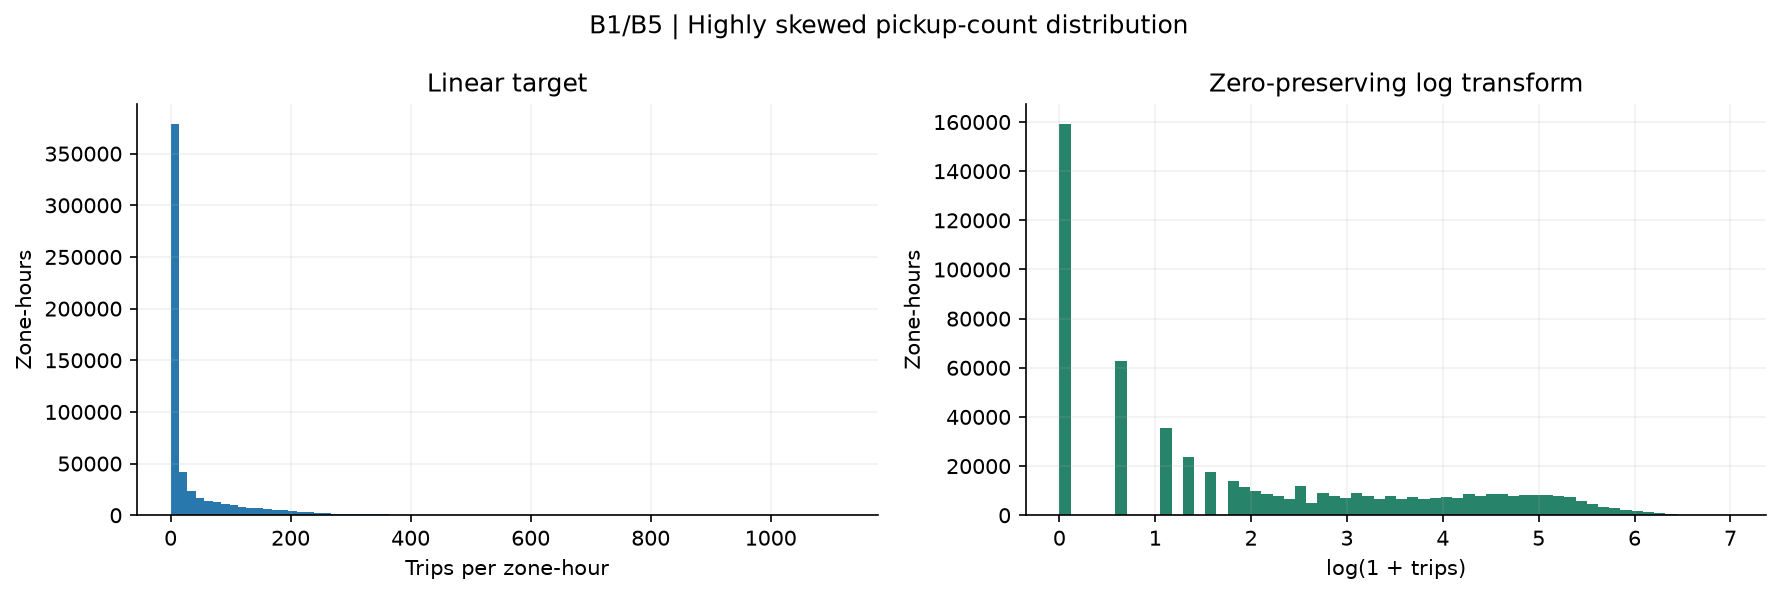

In [2]:
eda.issue63(data, zones)
display(pd.read_csv(eda.TABLES / 'A1_A8_data_checks.csv'))
display(pd.read_csv(eda.TABLES / 'A7_trip_reconciliation.csv'))
display(Image(filename=str(eda.FIGURES / 'B1_B5_target_histograms.png')))

## #64 ? Borough, airport and calendar patterns

Compare counts and per-zone rates; weekend ratios divide mean hourly pickups, not
unequal period totals. Mark the final six-day week and September's 23 observed days.
Time-band shares cover disjoint windows; monthly overlays also normalise the daily shape.

#64: borough, airport and calendar outputs saved; peak city hour 18:00.


,Borough,total,mean,rows,zones,trip_share_pct
0,Manhattan,19679535,68.297570,288144,69,90.571746
1,Queens,2048582,7.109577,288144,69,9.428254


,year_month,total,observed_days,mean_per_day,calendar_days,complete_month
0,2025-09,3086138,23,134179.91,30,False
1,2025-10,4121606,31,132955.03,31,True
2,2025-11,3893060,30,129768.67,30,True
3,2025-12,4010206,31,129361.48,31,True
4,2026-01,3458532,31,111565.55,31,True
5,2026-02,3158575,28,112806.25,28,True


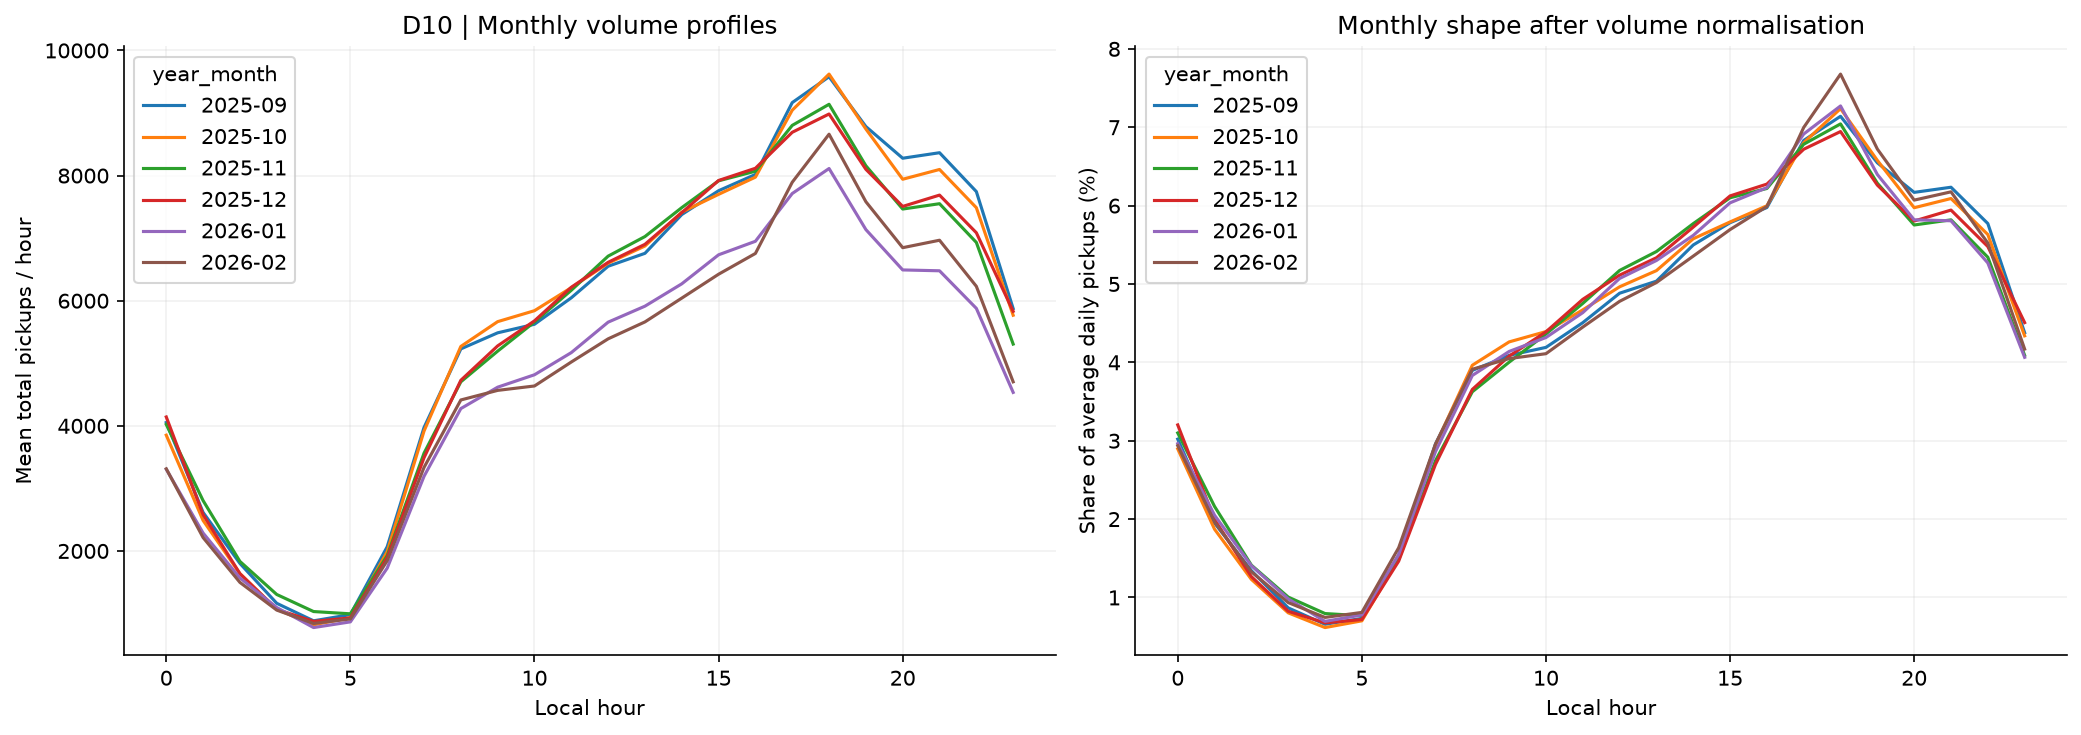

In [3]:
eda.issue64(data, zones)
display(pd.read_csv(eda.TABLES / 'C3_group_demand.csv'))
display(pd.read_csv(eda.TABLES / 'D4_monthly_trips_per_day.csv'))
display(Image(filename=str(eda.FIGURES / 'D10_monthly_hourly_profiles.png')))

## #66 ? Fleet planning and stability

Weekly consistency uses 24 complete weeks and compares each with a template excluding
itself. Adjacent-hour changes exclude transitions touching DST. Export all 240 top-ten
hourly rankings and all-zone empirical P95/P99. Weekend nights attach early Sat/Sun
to Fri/Sat evening; maps show centroids. Pickups alone do not specify fleet size.

#66: 24 full-week profiles; 31 hourly top-ten zones; fleet tables and charts saved.


,hour,top_5_share_pct,top_10_share_pct,top_20_share_pct
0,0,26.754045,42.434732,65.066143
1,1,33.131873,48.249249,68.973218
2,2,37.522876,52.295225,72.782415
3,3,36.086843,52.292490,71.694689
4,4,25.889978,39.145172,58.360643
5,5,23.964910,36.149926,54.904191
6,6,22.249631,36.585830,57.611127
7,7,21.280016,36.306838,58.457364
8,8,20.826938,35.497466,58.759339
9,9,21.287527,36.045968,60.585877


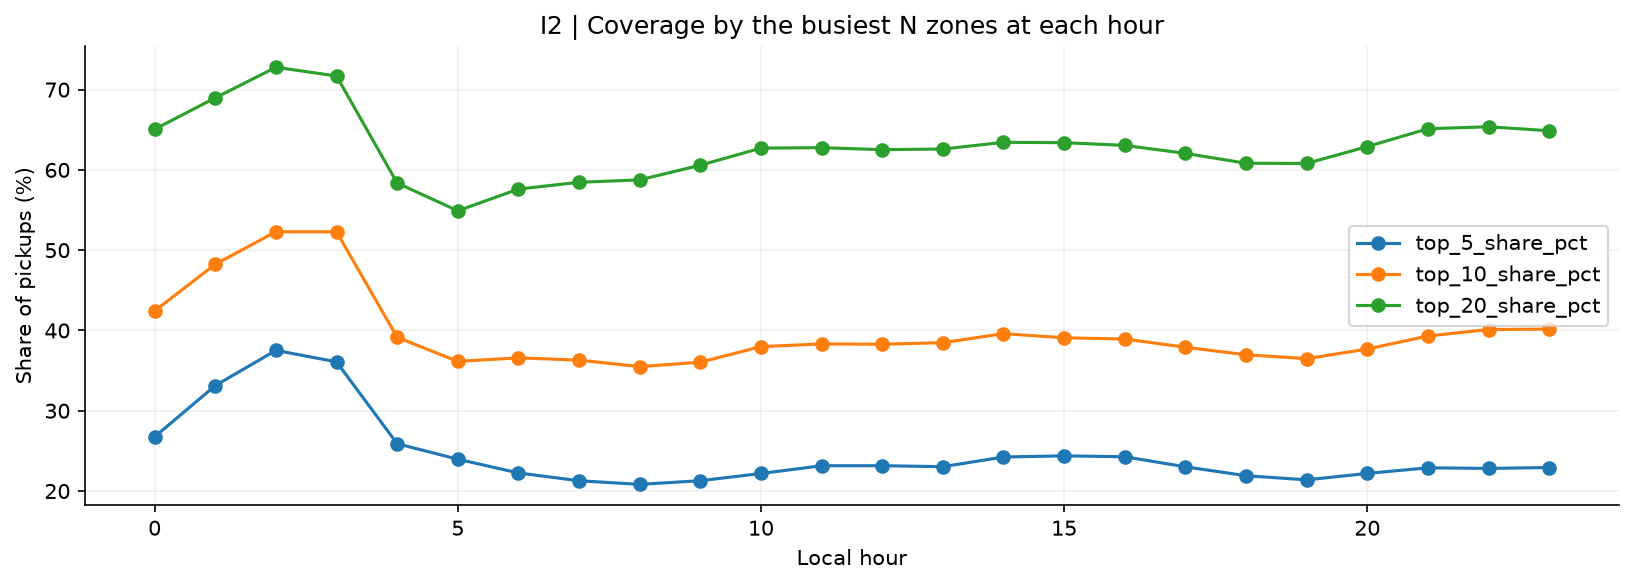

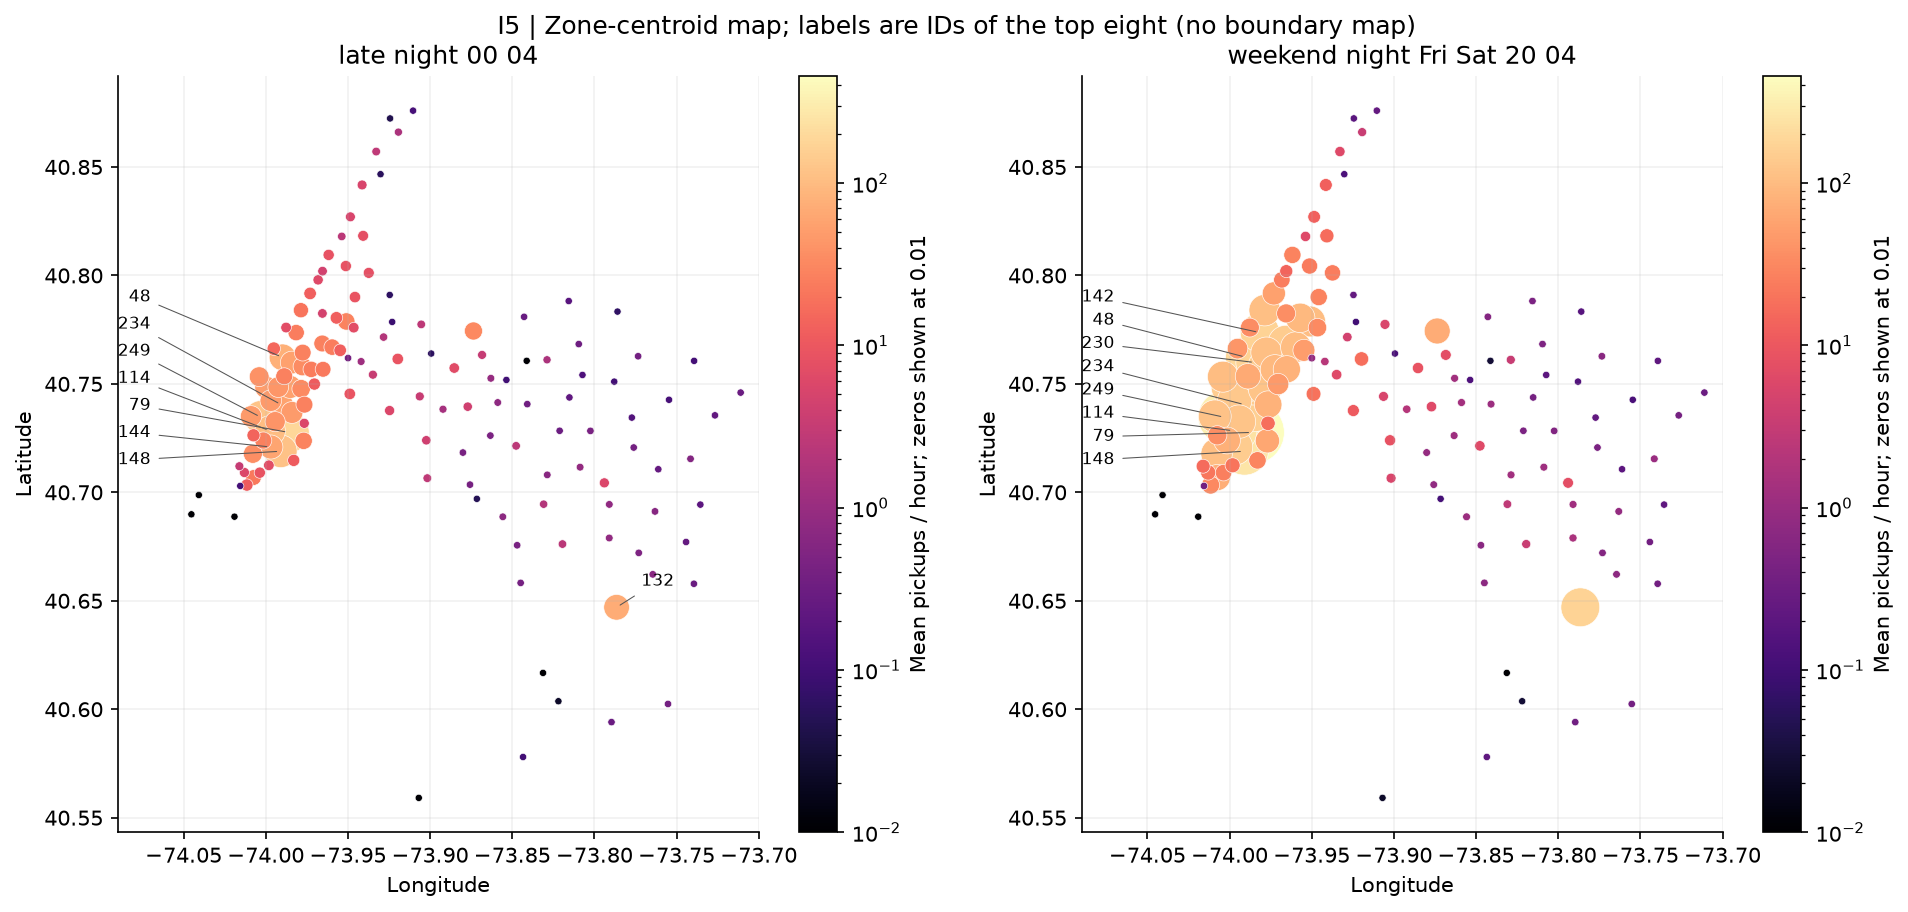

In [4]:
eda.issue66(data, zones)
display(pd.read_csv(eda.TABLES / 'I2_topN_hourly_coverage.csv'))
display(Image(filename=str(eda.FIGURES / 'I2_topN_coverage.png')))
display(Image(filename=str(eda.FIGURES / 'I5_night_hotspot_map.png')))

## #65 ? Holidays, special days and G9

Seven recurring federal holidays remain after warm-up. Compare each with up to six
nearby normal dates of the same weekday (?28 days, at least three), excluding
holidays, special dates, holiday periods and heavy-snow days. Export exact controls
and ?42-day sensitivity. New Year's Eve is Dec 31 20:00?Jan 1 04:59, matched to
normal Wednesday nights. The marathon and DST share a date; omit 01:00 from both
event and controls as a sensitivity. Comparisons are descriptive, not causal.

G9 is generated after all other assigned analysis, as requested. Suggested feature
families need chronological validation; full-period summaries cannot become forecast inputs.

#65: 7 holidays, 4 special days and cross-midnight NYE analysed; G9 saved last.


,date,event,scope,weekday,actual_trips,normal_mean_trips,pct_change,control_days,control_dates,normal_min_trips,normal_max_trips,normal_std_trips,window_days,pct_change_window42,control_dates_window42
0,2025-10-13,Columbus Day,All,Mon,104735,114189.500,-8.279658,6,2025-09-22;2025-09-29;2025-10-06;2025-10-20;20...,110307,121820,4239.3380,28,-8.279658,2025-09-22;2025-09-29;2025-10-06;2025-10-20;20...
3,2025-11-11,Veterans Day,All,Tue,123875,130882.330,-5.353918,6,2025-10-14;2025-10-21;2025-10-28;2025-11-04;20...,123806,138391,5287.5264,28,-5.353918,2025-10-14;2025-10-21;2025-10-28;2025-11-04;20...
6,2025-11-27,Thanksgiving Day,All,Thu,86029,155810.670,-44.786193,6,2025-11-06;2025-11-13;2025-11-20;2025-12-04;20...,147537,170253,8610.7877,28,-44.786193,2025-11-06;2025-11-13;2025-11-20;2025-12-04;20...
9,2025-12-25,Christmas Day,All,Thu,60817,143269.170,-57.550531,6,2025-12-04;2025-12-11;2025-12-18;2026-01-08;20...,111904,170253,22490.0070,28,-57.550531,2025-12-04;2025-12-11;2025-12-18;2026-01-08;20...
12,2026-01-01,New Year's Day,All,Thu,102562,143269.170,-28.413069,6,2025-12-04;2025-12-11;2025-12-18;2026-01-08;20...,111904,170253,22490.0070,28,-28.413069,2025-12-04;2025-12-11;2025-12-18;2026-01-08;20...
15,2026-01-19,Martin Luther King Jr. Day,All,Mon,93566,93566.000,0.000000,5,2026-01-05;2026-01-12;2026-01-26;2026-02-02;20...,63387,105267,17983.7740,28,-7.786162,2025-12-15;2026-01-05;2026-01-12;2026-01-26;20...
18,2026-02-16,Washington's Birthday,All,Mon,81311,90737.667,-10.388923,3,2026-01-26;2026-02-02;2026-02-09,63387,104814,23689.7660,28,-13.097706,2026-01-05;2026-01-12;2026-01-26;2026-02-02;20...


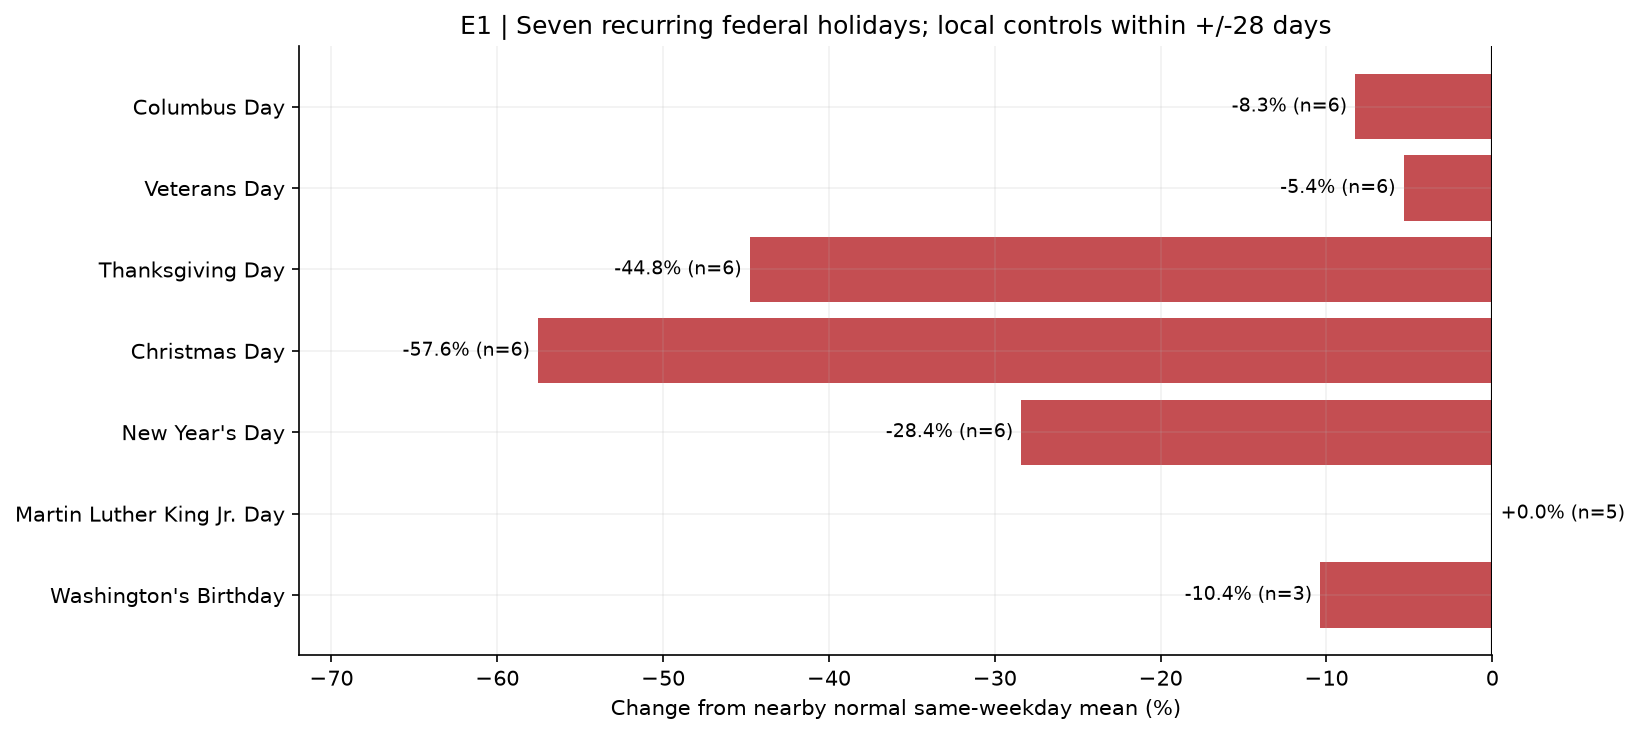

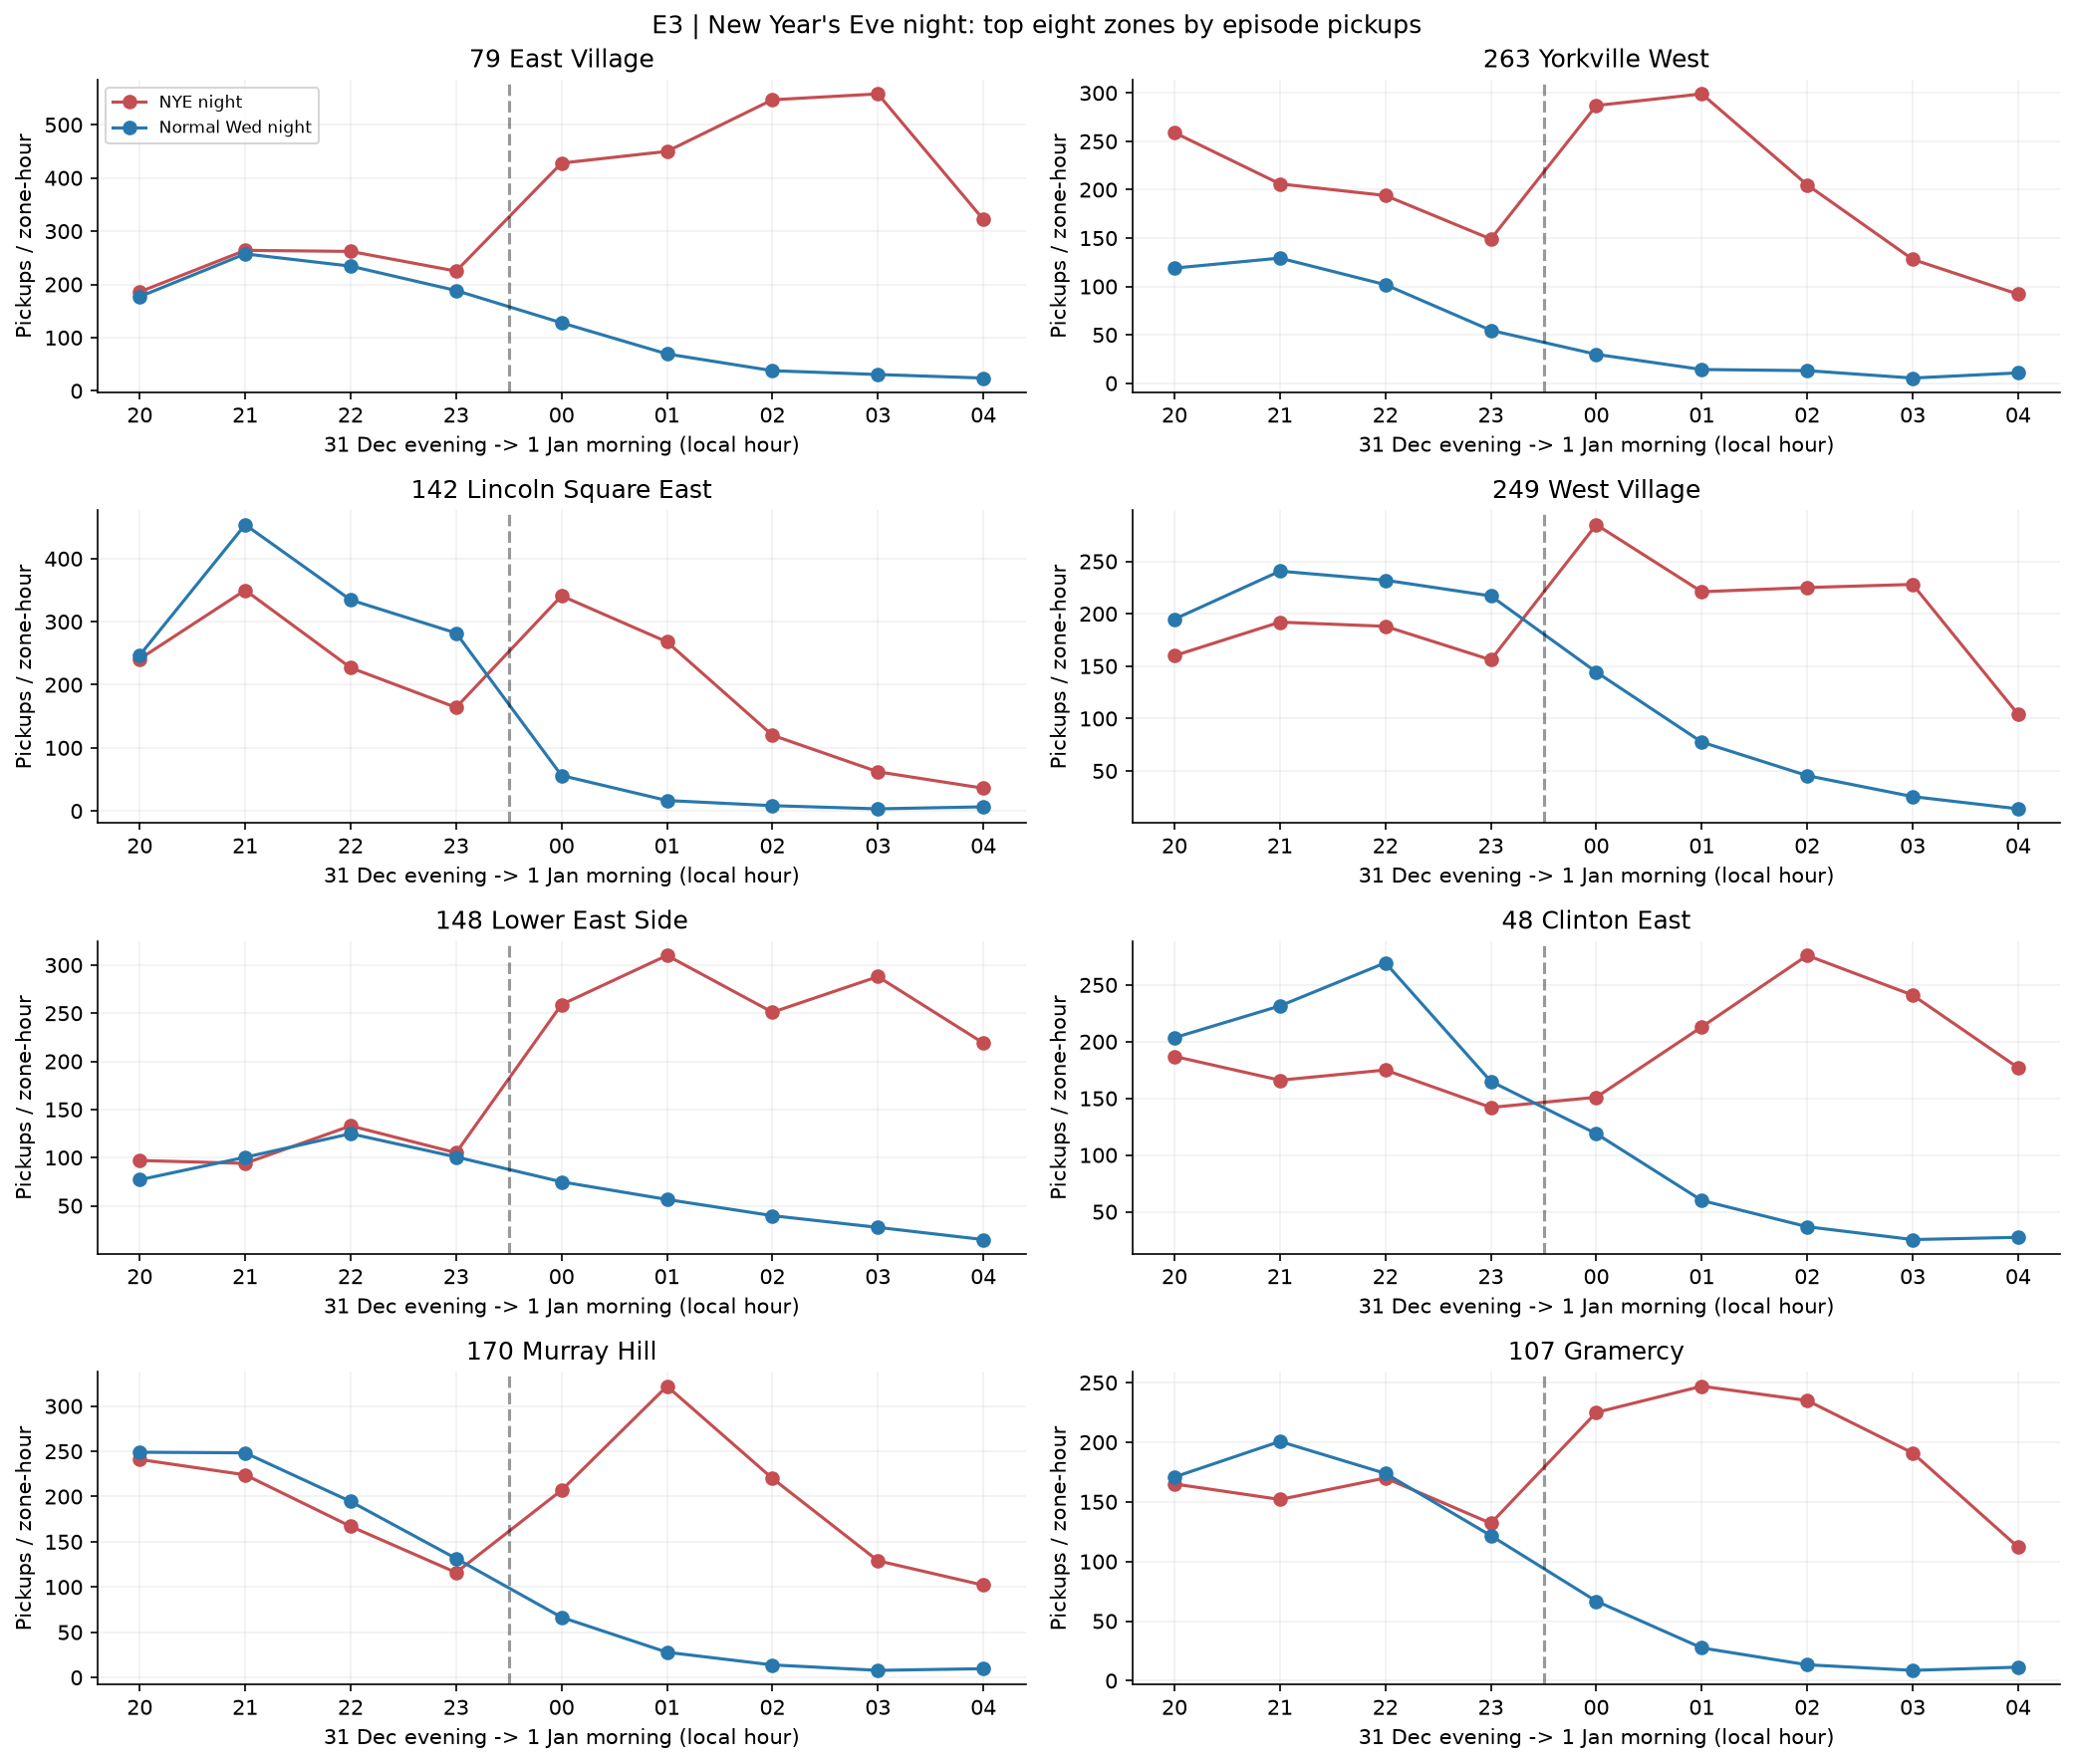

,candidate_feature,evidence_ids,definition,forecast_availability,validation_note
0,zone_x_hour_x_weekday,G9; D5/D6; C5; I4,Interactions of zone/service area with hour an...,Known calendar and location,Learn coefficients/encodings on training histo...
1,zone_x_weekend_night,G9; C9; I5,Friday/Saturday evening plus following early m...,Calendar known ahead,Assign 00--04 to the preceding evening date
2,holiday_name_x_hour,G9; E1; D8,Separate recurring holiday identity and hourly...,Published calendar,One observed example per holiday; test out of ...
3,holiday_period_and_distance,G9; E2,"Thanksgiving week, Dec20--Jan4, days before/af...",Published calendar,Fix event definitions before evaluation; avoid...
4,special_night_event,G9; E3/E4,"NYE night, Halloween night/spillover, Black Fr...",Published event calendar,Match cross-midnight windows; no post-event co...
5,DST_and_affected_lags,G9; A8,Combined DST hour and lag_24h/lag_168h contami...,Timezone rules known,Naive labels cannot recover the two physical h...
6,seasonal_time_features,G9; D3/D4; D10; H3,Cyclic hour/weekday and month or smooth season...,Calendar known ahead,Only six months: annual seasonality not establ...
7,zone_demand_level_and_sparsity,G9; B2/B4; H5,Historical zero share and demand level; option...,Past demand only,Compute on training history or lagged rolling ...
8,zone_weather_cell_metadata,G9; A8,Shared horizontal weather-cell ID for grouped ...,Static source metadata,Elevation may vary within cell; this is an eva...


In [5]:
eda.issue65(data, zones)
holidays = pd.read_csv(eda.TABLES / 'holiday_effects.csv')
display(holidays.loc[holidays.scope.eq('All')])
display(Image(filename=str(eda.FIGURES / 'E1_holiday_pct_change.png')))
display(Image(filename=str(eda.FIGURES / 'E3_new_year_night_profiles.png')))
display(pd.read_csv(eda.TABLES / 'G9_suggested_features.csv'))

## Validate and browse all artifacts

Validate all 37 assigned IDs, input fingerprints, figure files, links and exported
statistics against the original feature rows. Validation includes holiday controls,
night assignments, top-N coverage, percentile values and period denominators.

In [6]:
eda.write_manifest()
validate()
catalog = pd.read_csv(eda.TABLES / 'artifact_catalog.csv')
display(catalog)
display(Markdown('[Complete findings](../EDA_doc/EDA_findings.md) ? [Reproduction guide](../EDA_doc/README.md)'))

Validated 37 assigned IDs, 35 figures, 47 tables, 7 input hashes, and source-derived calendar/ranking/holiday/night statistics.


,path,type,ids_in_filename
0,figures/A2_rows_per_zone.png,png,A2
1,figures/A2_zero_hour_heatmap.png,png,A2
2,figures/A8_dst_comparison.png,png,A8
3,figures/B1_B3_ecdf.png,png,B1;B3
4,figures/B1_B5_target_histograms.png,png,B1;B5
...,...,...,...
77,tables/I2_topN_hourly_coverage.csv,csv,I2
78,tables/I4_airport_manhattan_hourly.csv,csv,I4
79,tables/I5_night_hotspots.csv,csv,I5
80,tables/I6_boro_zone_hourly.csv,csv,I6


[Complete findings](../EDA_doc/EDA_findings.md) ? [Reproduction guide](../EDA_doc/README.md)